**AST** (*Audio Spectrogram Transformer*, `MIT/ast-finetuned-audioset-10-10-0.4593`, 87 M de paramètres) est un Transformer qui « regarde » le spectrogramme du son. Il a été entraîné sur **AudioSet** (2 millions d'extraits YouTube) à reconnaître **527 types de sons** : parole, musique, cris, explosions, véhicules, silence…

Ce notebook l'utilise de deux façons :
1. **Reconnaissance des émotions** : AST résume chaque extrait en un vecteur de *768 nombres* (modèle gelé), puis le classifieur commun de `utils.py` apprend les 8 émotions. On teste aussi les *527 probabilités AudioSet* comme descripteurs.
2. **Nature des sons** : les 527 probabilités disent ce qu'on entend. On vérifie ainsi ce que contiennent vraiment les extraits *sans parole* détectés par b0 (musique ? cris ? bruitages ? silence ?).

## 0. Préparation

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CODE = Path("/content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain")
else:
    CODE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "audio" / "ghislain" / "utils.py").exists()) / "audio" / "ghislain"
sys.path.insert(0, str(CODE))

import importlib
import utils
importlib.reload(utils)

P = utils.setup()            # audio + annotations

Mounted at /content/drive
Copie du zip depuis le Drive (~2-3 min)...
$ cp "/content/drive/MyDrive/Projet Multimédia/PROJET_SID_2026.zip" /content/PROJET_SID_2026.zip
Décompression de : audio, annotation
$ mkdir -p /content/data && unzip -q -o /content/PROJET_SID_2026.zip 'PROJET_SID_2026/movie/audio/*' 'PROJET_SID_2026/movie/annotation/*' -d /content/data
Données  : /content/data/PROJET_SID_2026
Résultats: /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Test rapide : mettre par ex. 20 (extraits par ensemble). None = tous les extraits.
ECHANTILLON = None

meta = utils.load_metadata(P)
SUFFIXE = ""
if ECHANTILLON:
    meta = (pd.concat([meta[meta.split == s].sample(ECHANTILLON, random_state=utils.SEED)
                       for s in utils.SPLITS]).sort_values("video_id").reset_index(drop=True))
    SUFFIXE = "_echantillon"
tr, dv, te = (meta.split == s for s in utils.SPLITS)
y = meta.label.to_numpy()
print(len(meta), "extraits |", meta.split.value_counts().to_dict())

3088 extraits | {'train': 2207, 'dev': 442, 'test': 439}


## 1. Extraction des représentations AST

AST travaille sur des fenêtres d'environ **10 secondes**. Les extraits plus longs (jusqu'à 30 s) sont découpés en fenêtres de même longueur ; pour chaque extrait on garde :
- la **moyenne** des vecteurs de 768 nombres des fenêtres (représentation globale) ;
- le **maximum** des 527 probabilités AudioSet (un son est « présent » s'il apparaît dans au moins une fenêtre).

In [3]:
import torch
from transformers import ASTFeatureExtractor, ASTForAudioClassification

MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SR, WIN, BATCH = 16000, 10 * 16000, 16

extracteur = ASTFeatureExtractor.from_pretrained(MODEL_ID)
ast = ASTForAudioClassification.from_pretrained(MODEL_ID).to(DEVICE).eval()
LABELS = [ast.config.id2label[i] for i in range(ast.config.num_labels)]
D_EMB = ast.config.hidden_size
print("Calcul sur", DEVICE, "|", len(LABELS), "catégories AudioSet | vecteur de", D_EMB)


@torch.no_grad()
def vecteurs_ast(chemins):
    # 1) découpe en fenêtres de <= 10 s
    fenetres, proprietaire = [], []
    for i, c in enumerate(chemins):
        son = utils.load_audio(c, SR)
        n = max(1, int(np.ceil(len(son) / WIN)))
        for morceau in np.array_split(son, n):
            fenetres.append(morceau)
            proprietaire.append(i)
    # 2) AST par lots
    embs, probas = [], []
    for b in range(0, len(fenetres), BATCH):
        x = extracteur(fenetres[b:b + BATCH], sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        pooled = ast.audio_spectrogram_transformer(x).pooler_output     # (lot, 768)
        logits = ast.classifier(pooled)                                  # (lot, 527)
        embs.append(pooled.cpu().numpy())
        probas.append(torch.sigmoid(logits).cpu().numpy())
    embs, probas, proprietaire = np.concatenate(embs), np.concatenate(probas), np.array(proprietaire)
    # 3) une ligne par extrait : moyenne des vecteurs, maximum des probabilités
    return np.stack([np.concatenate([embs[proprietaire == i].mean(0), probas[proprietaire == i].max(0)])
                     for i in range(len(chemins))])


Z = utils.extract_features("ast" + SUFFIXE, meta, vecteurs_ast, P)
X_emb, X_tags = Z[:, :D_EMB], Z[:, D_EMB:]
print("vecteurs :", X_emb.shape, "| probabilités AudioSet :", X_tags.shape)

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Calcul sur cpu | 527 catégories AudioSet | vecteur de 768


extraction ast:   0%|          | 0/16 [00:00<?, ?it/s]

vecteurs : (3088, 768) | probabilités AudioSet : (3088, 527)


**Embeddings**

In [4]:
extracteur = ASTFeatureExtractor.from_pretrained(MODEL_ID)                 # son -> spectrogramme
ast = ASTForAudioClassification.from_pretrained(MODEL_ID).to(DEVICE).eval()

@torch.no_grad()
def vecteurs_ast(chemins):
    # 1) découpe en fenêtres de <= 10 s
    fenetres, proprietaire = [], []
    for i, c in enumerate(chemins):
        son = utils.load_audio(c, SR)                     # mono, 16 kHz
        n = max(1, int(np.ceil(len(son) / WIN)))
        for morceau in np.array_split(son, n):
            fenetres.append(morceau)
            proprietaire.append(i)
    # 2) AST par lots
    embs, probas = [], []
    for b in range(0, len(fenetres), BATCH):
        x = extracteur(fenetres[b:b + BATCH], sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        pooled = ast.audio_spectrogram_transformer(x).pooler_output     # (lot, 768)  <- L'EMBEDDING
        logits = ast.classifier(pooled)                                  # (lot, 527)
        embs.append(pooled.cpu().numpy())
        probas.append(torch.sigmoid(logits).cpu().numpy())
    ...
    # 3) une ligne par extrait : moyenne des embeddings, maximum des probabilités
    return np.stack([np.concatenate([embs[proprietaire == i].mean(0), probas[proprietaire == i].max(0)])
                     for i in range(len(chemins))])

Z = utils.extract_features("ast", meta, vecteurs_ast, P)     # calcul + sauvegarde sur le Drive
X_emb, X_tags = Z[:, :768], Z[:, 768:]

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

extraction ast:   0%|          | 0/16 [00:00<?, ?it/s]

## 2. Reconnaissance des émotions

Même procédure que les références de b00 : classifieur commun (régression logistique pondérée), `C` choisi sur le **dev**, mesure finale sur le **test**.


=== ast : C retenu sur le dev = 0.0001
[ast | dev] F1 macro = 0.236 | acc. équilibrée = 0.253 | accuracy = 0.242
   F1 macro avec parole = 0.231 | sans parole = 0.175
   F1 par émotion : amusement 0.27, awe 0.23, contentment 0.15, excitement 0.22, anger 0.23, disgust 0.13, fear 0.31, sadness 0.35
[ast | test] F1 macro = 0.248 | acc. équilibrée = 0.269 | accuracy = 0.271
   F1 macro avec parole = 0.259 | sans parole = 0.175
   F1 par émotion : amusement 0.32, awe 0.14, contentment 0.23, excitement 0.19, anger 0.26, disgust 0.16, fear 0.46, sadness 0.22


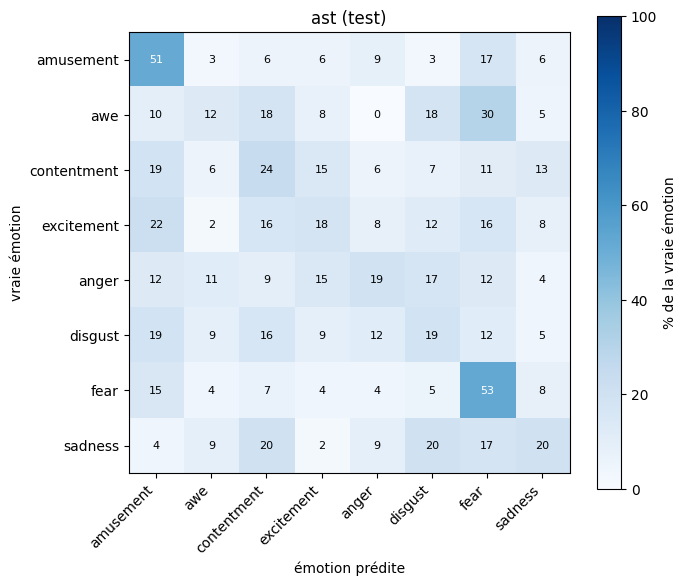


=== ast_tags : C retenu sur le dev = 0.0001
[ast_tags | dev] F1 macro = 0.195 | acc. équilibrée = 0.205 | accuracy = 0.201
   F1 macro avec parole = 0.200 | sans parole = 0.147
   F1 par émotion : amusement 0.26, awe 0.15, contentment 0.06, excitement 0.21, anger 0.27, disgust 0.11, fear 0.19, sadness 0.31
[ast_tags | test] F1 macro = 0.217 | acc. équilibrée = 0.228 | accuracy = 0.246
   F1 macro avec parole = 0.199 | sans parole = 0.194
   F1 par émotion : amusement 0.34, awe 0.08, contentment 0.20, excitement 0.18, anger 0.35, disgust 0.09, fear 0.39, sadness 0.10


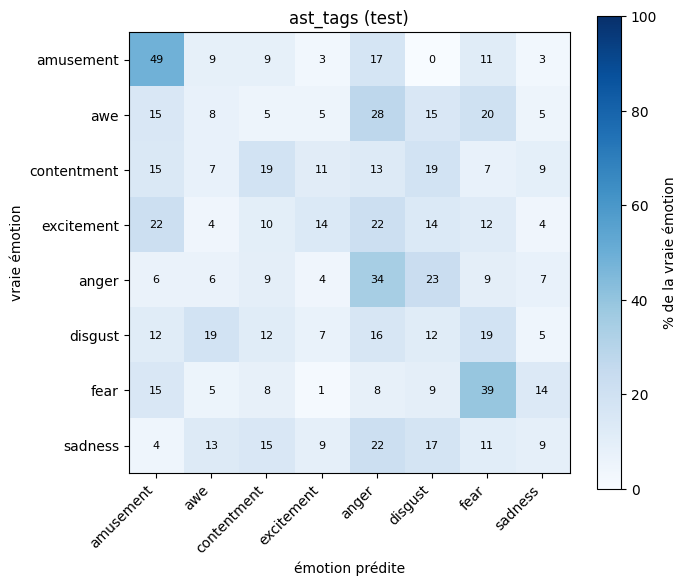

In [5]:
resultats_ast = {}
for nom, X in (("ast", X_emb), ("ast_tags", X_tags)):
    nom += SUFFIXE
    clf, C, scores = utils.select_C(X[tr], y[tr], X[dv], y[dv])
    print(f"\n=== {nom} : C retenu sur le dev = {C}")
    for split, m in (("dev", dv), ("test", te)):
        proba = clf.predict_proba(X[m])
        res = utils.evaluate(y[m], proba, parole=meta.parole[m], name=nom, split=split)
        utils.log_results(res, P)
        utils.save_preds(meta.video_id[m], proba, nom, split, P)
    resultats_ast[nom] = clf
    utils.plot_confusion(y[te], clf.predict_proba(X[te]), f"{nom} (test)", P, f"cm_{nom}_test.png")
    plt.show()

In [6]:
res = pd.read_csv(P.OUT / "resultats.csv")
cols = ["modele", "split", "f1_macro", "balanced_acc", "f1_macro_avec_parole", "f1_macro_sans_parole",
        "f1_anger", "f1_fear", "f1_sadness", "f1_amusement"]
display(res[cols].sort_values(["split", "f1_macro"], ascending=[True, False]).round(3))

,modele,split,f1_macro,balanced_acc,f1_macro_avec_parole,f1_macro_sans_parole,f1_anger,f1_fear,f1_sadness,f1_amusement
34,fus_precoce_ast_whisper_caption_couleurs,dev,0.338,0.353,0.331,0.247,0.355,0.355,0.390,0.361
12,fus_tardive_ast_caption,dev,0.337,0.356,0.285,0.408,0.338,0.388,0.318,0.421
14,fus_tardive_ast_caption_annot,dev,0.337,0.356,0.285,0.408,0.338,0.388,0.318,0.421
24,fus_precoce_ast_clap_caption_couleurs,dev,0.337,0.351,0.295,0.373,0.333,0.382,0.379,0.384
8,caption_minilm,dev,0.332,0.350,0.279,0.404,0.338,0.391,0.315,0.405
36,fus_tardive_ast_whisper,dev,0.319,0.329,0.312,0.222,0.367,0.318,0.439,0.338
32,fus_precoce_ast_caption_couleurs,dev,0.319,0.337,0.280,0.342,0.303,0.345,0.403,0.400
10,fus_precoce_ast_caption,dev,0.317,0.334,0.278,0.342,0.301,0.348,0.400,0.395
28,whisper_enc,dev,0.310,0.319,0.299,0.210,0.349,0.347,0.449,0.319
30,fus_precoce_ast_whisper,dev,0.287,0.299,0.269,0.246,0.329,0.312,0.387,0.351


**Interprétation :**
- **AST (vecteurs de 768 nombres)** : F1 macro de **0,24 (dev)** et **0,25 (test)**, environ **deux fois le hasard** (~0,12) et nettement au-dessus de la référence durée + parole (0,15 / 0,11). AST a donc vraiment appris à reconnaître des émotions dans le son.
- **AST (527 probabilités de sons)** : un peu moins bon, avec **0,20 (dev)** et **0,22 (test)**. Savoir **quels sons** sont présents capte déjà une grande partie de l'émotion.
- **Les émotions les mieux reconnues** par AST (test) sont `fear` (0,46), `amusement` (0,32) et `anger` (0,26). **Les moins bien reconnues** sont `awe` (0,14) et `disgust` (0,16).
- **Le modèle couvre aussi les extraits sans parole** : F1 macro de **0,18** sans parole (contre 0,07 pour la référence durée + parole) et de 0,26 avec parole.
- **Le C retenu est très petit (C = 0,0001)** : avec 768 descripteurs pour seulement 2 207 extraits, le classifieur doit être fortement régularisé pour ne pas surapprendre. C'est le plus petit C dont le score dev est à moins de 0,01 du meilleur.

## 3. Que contiennent vraiment les extraits ?

On regroupe les 527 catégories AudioSet en 5 familles. Le score d'une famille est la probabilité de sa catégorie la plus probable ; la **famille dominante** est celle qui a le score le plus élevé (« indéterminé » si aucune ne dépasse 0,1).

In [7]:
FAMILLES = {
    "parole": ["Speech", "Male speech, man speaking", "Female speech, woman speaking",
               "Child speech, kid speaking", "Conversation", "Narration, monologue", "Whispering"],
    "voix non verbale (cris, pleurs, rires)": [
               "Screaming", "Shout", "Yell", "Children shouting", "Battle cry", "Crying, sobbing",
               "Wail, moan", "Whimper", "Laughter", "Giggle", "Gasp", "Groan", "Sigh", "Breathing"],
    "musique": ["Music", "Singing", "Musical instrument", "Orchestra"],
    "bruitages": ["Explosion", "Gunshot, gunfire", "Machine gun", "Boom", "Bang", "Vehicle", "Car", "Engine",
                  "Helicopter", "Aircraft", "Siren", "Door", "Slam", "Knock", "Walk, footsteps", "Glass",
                  "Shatter", "Smash, crash", "Breaking", "Crack", "Thump, thud", "Thunder", "Fire",
                  "Wind", "Rain", "Animal"],
    "silence / ambiance": ["Silence", "Inside, small room", "Inside, large room or hall",
                           "Outside, urban or manmade", "Outside, rural or natural"],
}
idx = {l: i for i, l in enumerate(LABELS)}
absents = [l for f in FAMILLES.values() for l in f if l not in idx]
assert not absents, f"catégories inconnues : {absents}"

fam = pd.DataFrame({f: X_tags[:, [idx[l] for l in ls]].max(1) for f, ls in FAMILLES.items()})
fam.insert(0, "video_id", meta.video_id.values)
scores_f = fam[list(FAMILLES)]
fam["dominante"] = np.where(scores_f.max(axis=1) >= 0.1, scores_f.idxmax(axis=1), "indéterminé")
fam["top3"] = [", ".join(f"{LABELS[j]} {p[j]:.2f}" for j in np.argsort(-p)[:3]) for p in X_tags]
sons = (meta[["video_id", "film_id", "split", "emotion", "parole", "statut"]]
        .rename(columns={"parole": "parole_vad"})          # parole détectée par b0 (VAD)
        .merge(fam, on="video_id"))
print(sons.dominante.value_counts().to_string())

dominante
parole                                    1905
musique                                   1000
bruitages                                  106
indéterminé                                 42
voix non verbale (cris, pleurs, rires)      25
silence / ambiance                          10


### 3.1 Contrôle de cohérence avec b0
Le score « parole » d'AST doit être nettement plus élevé sur les extraits où la détection de parole de b0 a trouvé de la voix.

In [8]:
display(sons.groupby("parole_vad")[list(FAMILLES)].mean().round(2)
        .rename(index={True: "avec parole (b0)", False: "sans parole (b0)"}))

,parole,"voix non verbale (cris, pleurs, rires)",musique,bruitages,silence / ambiance
parole_vad,,,,,
sans parole (b0),0.17,0.02,0.38,0.10,0.02
avec parole (b0),0.58,0.04,0.27,0.06,0.03


**Interprétation :** Nous avons vérifié la détection de parole avec un second modèle indépendant, AST. Le score de parole est de 0,58 sur les extraits avec parole, contre 0,17 sur les autres : les deux méthodes concordent, ce qui valide notre séparation avec et sans parole(cela valide la détection de parole de b0).

### 3.2 Les extraits sans parole : qu'entend-on ?

986 extraits sans parole détectée


,% des extraits sans parole
dominante,
musique,68.5
parole,15.3
bruitages,9.8
indéterminé,4.0
"voix non verbale (cris, pleurs, rires)",1.5
silence / ambiance,0.9


dominante,bruitages,indéterminé,musique,parole,silence / ambiance,"voix non verbale (cris, pleurs, rires)"
emotion,,,,,,
amusement,5.6,0.0,84.4,10.0,0.0,0.0
awe,13.5,7.3,66.7,9.4,2.1,1.0
contentment,6.2,6.2,72.9,9.4,2.1,3.1
excitement,6.8,0.0,64.9,27.0,1.4,0.0
anger,11.9,1.2,65.6,20.0,0.6,0.6
disgust,16.7,11.1,57.4,14.8,0.0,0.0
fear,10.5,3.9,66.2,17.0,0.0,2.3
sadness,7.2,5.4,71.2,10.8,2.7,2.7


% des extraits sans parole où chaque famille est présente (score >= 0,2) :


,parole,"voix non verbale (cris, pleurs, rires)",musique,bruitages,silence / ambiance
emotion,,,,,
amusement,41.1,0.0,88.9,11.1,0.0
awe,13.5,2.1,69.8,20.8,1.0
contentment,17.7,5.2,76.0,15.6,0.0
excitement,48.6,0.0,75.7,8.1,0.0
anger,43.8,3.1,71.2,21.2,1.2
disgust,25.9,0.0,64.8,16.7,0.0
fear,33.1,3.6,72.8,20.3,0.0
sadness,21.6,4.5,75.7,9.9,0.0


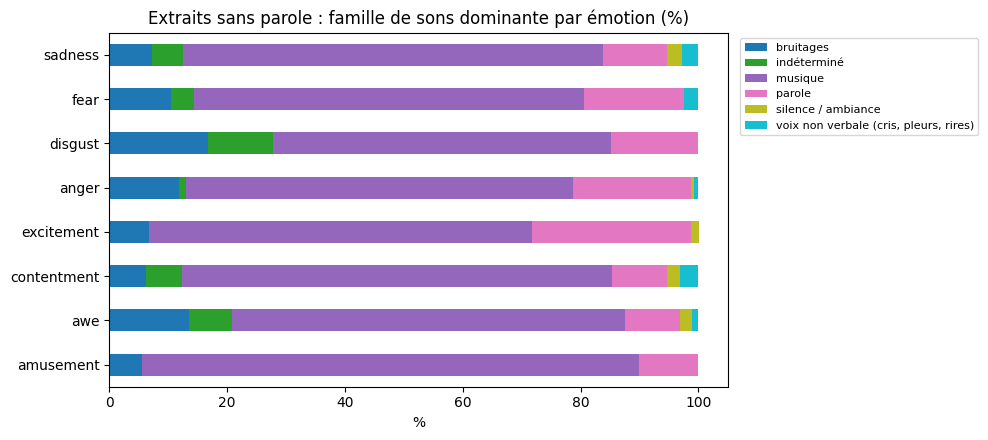

In [9]:
sp = sons[~sons.parole_vad]
print(f"{len(sp)} extraits sans parole détectée")
display((100 * sp.dominante.value_counts(normalize=True)).round(1).to_frame("% des extraits sans parole"))

EMO = utils.EMOTIONS
dom = (100 * pd.crosstab(sp.emotion, sp.dominante, normalize="index")).reindex(EMO).round(1)
display(dom)

presence = (100 * sp.groupby("emotion")[list(FAMILLES)].apply(lambda d: (d >= 0.2).mean())).reindex(EMO).round(1)
print("% des extraits sans parole où chaque famille est présente (score >= 0,2) :")
display(presence)

fig, ax = plt.subplots(figsize=(10, 4.5))
dom.plot.barh(stacked=True, ax=ax, colormap="tab10")
ax.set(title="Extraits sans parole : famille de sons dominante par émotion (%)", xlabel="%", ylabel="")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(P.FIGS / f"ast_sons_sans_parole{SUFFIXE}.png", dpi=150)
plt.show()

### 3.3 Exemples : extraits `fear` sans parole

In [10]:
display(sp[sp.emotion == "fear"].sample(min(10, (sp.emotion == "fear").sum()), random_state=0)
        [["video_id", "dominante", "top3"]])

,video_id,dominante,top3
587,00069_clip_004,musique,"Music 0.54, Scary music 0.15, Ambient music 0.09"
427,00051_clip_001,bruitages,"Train 0.20, Clickety-clack 0.18, Rail transpor..."
581,00066_clip_045,"voix non verbale (cris, pleurs, rires)","Battle cry 0.36, Crowd 0.34, Music 0.34"
1469,00177_clip_033,musique,"Music 0.41, Speech 0.40, Smash, crash 0.08"
3063,00374_clip_008,musique,"Music 0.52, Speech 0.44, Thump, thud 0.30"
1360,00161_clip_013,"voix non verbale (cris, pleurs, rires)","Gasp 0.66, Snort 0.58, Music 0.36"
2355,00287_clip_029,musique,"Music 0.65, Speech 0.27, Heart sounds, heartbe..."
472,00055_clip_019,parole,"Speech 0.39, Music 0.23, Smash, crash 0.06"
1335,00158_clip_006,musique,"Music 0.41, Speech 0.06, Animal 0.02"
2215,00271_clip_057,musique,"Music 0.64, Speech 0.12, Scary music 0.03"


### 3.4 L'ambiance de la musique

AudioSet contient 7 catégories d'**ambiance musicale** (musique joyeuse, drôle, triste, tendre, excitante, en colère, effrayante). Ce sont des indices directs de l'émotion d'une scène : on regarde leur probabilité moyenne pour chacune de nos 8 émotions (tous les extraits).

,Happy music,Funny music,Sad music,Tender music,Exciting music,Angry music,Scary music
emotion,,,,,,,
amusement,3.28,3.84,1.36,1.61,2.74,0.92,0.24
awe,0.86,0.84,1.15,1.07,0.94,1.24,0.69
contentment,1.06,1.13,1.18,1.24,0.74,0.39,0.35
excitement,1.38,0.95,1.16,1.25,1.03,0.64,0.37
anger,0.50,0.59,0.49,0.57,0.74,1.03,0.91
disgust,0.72,0.60,0.86,0.86,0.81,0.74,0.47
fear,0.75,0.71,0.87,0.80,1.07,1.96,2.78
sadness,0.64,0.61,1.59,1.28,0.62,0.59,1.08


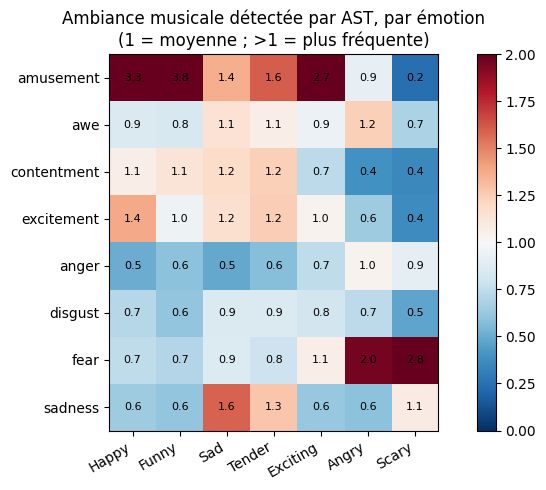

In [11]:
AMBIANCES = ["Happy music", "Funny music", "Sad music", "Tender music",
             "Exciting music", "Angry music", "Scary music"]
amb = pd.DataFrame(X_tags[:, [idx[a] for a in AMBIANCES]], columns=AMBIANCES)
amb["emotion"] = meta.emotion.values
moy = amb.groupby("emotion")[AMBIANCES].mean().reindex(utils.EMOTIONS)
# rapport à la moyenne générale : > 1 = ambiance sur-représentée pour cette émotion
ratio = moy / amb[AMBIANCES].mean()
display(ratio.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(ratio.to_numpy(), cmap="RdBu_r", vmin=0, vmax=2)
ax.set_xticks(range(len(AMBIANCES)), [a.replace(" music", "") for a in AMBIANCES], rotation=30, ha="right")
ax.set_yticks(range(8), utils.EMOTIONS)
for i in range(8):
    for j in range(len(AMBIANCES)):
        ax.text(j, i, f"{ratio.iat[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set(title="Ambiance musicale détectée par AST, par émotion\n(1 = moyenne ; >1 = plus fréquente)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(P.FIGS / f"ast_ambiance_musicale{SUFFIXE}.png", dpi=150)
plt.show()

**Interprétation :** le tableau compare la présence de chaque ambiance musicale à sa moyenne (1 = moyenne). Les associations sont très cohérentes :
- **`amusement`** : musique **drôle** (×3,8), **joyeuse** (×3,3) et **excitante** (×2,7) ;
- **`fear`** : musique **effrayante** (×2,8) et **en colère** (×2,0) ;
- **`sadness`** : musique **triste** (×1,6) et **tendre** (×1,3) ;
- **`anger`** : toutes les ambiances sont sous la moyenne. La colère passe surtout par les **dialogues**, pas par la musique.

**Conclusion :** la musique de film est un indicateur direct de l'émotion d'une scène, ce qui explique pourquoi AST, qui « comprend » la musique, reconnaît bien `amusement` et `fear`.

## 4. Export

In [12]:
cols = ["video_id", "film_id", "split", "emotion", "parole_vad", "statut", *FAMILLES, "dominante", "top3"]
sons[cols].sort_values("video_id").to_csv(P.OUT / f"ast_sons{SUFFIXE}.csv", index=False)
print("écrit :", P.OUT / f"ast_sons{SUFFIXE}.csv")
print("prédictions :", sorted(p.name for p in P.PREDS.glob(f"ast*{SUFFIXE}_*.csv")))

écrit : /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain/ast_sons.csv
prédictions : ['ast_dev.csv', 'ast_tags_dev.csv', 'ast_tags_test.csv', 'ast_test.csv']
